In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import py_functions.mineralogy as mineral
import py_functions.normalize as norm
import numpy as np
from pathlib import Path

In [ ]:
#import formatted PIXL data from parquet into DataFrame
pixl_data = pd.read_parquet("pixl_cache/processed_data/master_merged.parquet")
#directory for saving the plots to
plot_dir = Path("pixl_cache/plots")

In [ ]:
#check targets for amount of data
target_counts = (
    pixl_data
    .groupby("TARGET")
    .size()
    .reset_index(name="N_POINTS")
    .sort_values("N_POINTS", ascending=False)
)

print(target_counts)

#write target names and point count to .csv file
targets_path = Path("pixl_cache/targets/targets_points.csv")
target_counts_df = pd.DataFrame(data=target_counts, columns=["TARGET","N_POINTS"])
target_counts_df.to_csv(targets_path, index=False)

In [ ]:
#plot the distribution for a selected locality and oxide (single Channel)
target_name = "Alfalfa"
target_oxide = "MgO_wt%"
plotname = f"{target_name}_{target_oxide}.svg"

#plot the data
target = pixl_data[pixl_data["TARGET"] == target_name]
plt.scatter(
    target["x"],
    target["y"],
    c=target[target_oxide],
    cmap="Greens",
    marker="s",
    s=4
)

plottitle = f"Element Map: {target_name} {len(target["x"])}px"

plt.colorbar(label=target_oxide)
plt.xlabel("X")
plt.ylabel("Y")
plt.axis("equal")
plt.title(plottitle)
plt.savefig(
    plot_dir / plotname,
    format="svg"
)
plt.show()

In [ ]:
# Create a Chemical Map with RGB color encoded oxide concentrations
target_name = "Dourbes"


##plot the data
target = pixl_data[pixl_data["TARGET"] == target_name]
fig, ax = plt.subplots(figsize=(8, 6))

#set colors here
red_oxide = "FeO-T_wt%"
green_oxide = "MgO_wt%"
blue_oxide = "SiO2_wt%"

red_crop = red_oxide[:red_oxide.rfind("_")]
green_crop = green_oxide[:green_oxide.rfind("_")]
blue_crop = blue_oxide[:blue_oxide.rfind("_")]


r = norm.normalize_percentile(target[red_oxide])
g = norm.normalize_percentile(target[green_oxide])
b = norm.normalize_percentile(target[blue_oxide])

rgb = np.column_stack([r, g, b])

plotname = f"{target_name}_RGB_{red_crop}{green_crop}{blue_crop}.svg"

#convert m to mm for axis and set the first spot to (0,0)
ax.scatter(
    (target["x"]-min(target["x"]))*1e+3,
    (target["y"]-min(target["y"]))*1e+3,
    c=rgb,
    marker="o",
    s=8
)

ax.set_xlabel("X [mm]")
ax.set_ylabel("Y [mm]")
ax.set_aspect("equal")

ax.set_title(
    f"{target_name}\n"
    f"R: {red_oxide}, "
    f"G: {green_oxide}, "
    f"B: {blue_oxide}"
)
plt.savefig(plot_dir / plotname, format="svg")
plt.show()
plt.close(fig)

In [ ]:
# Insert the correct filename of the domain data
domain_data = pd.read_csv("pixl_cache/target_analysis/_AllTargets_Summary_T30.csv")

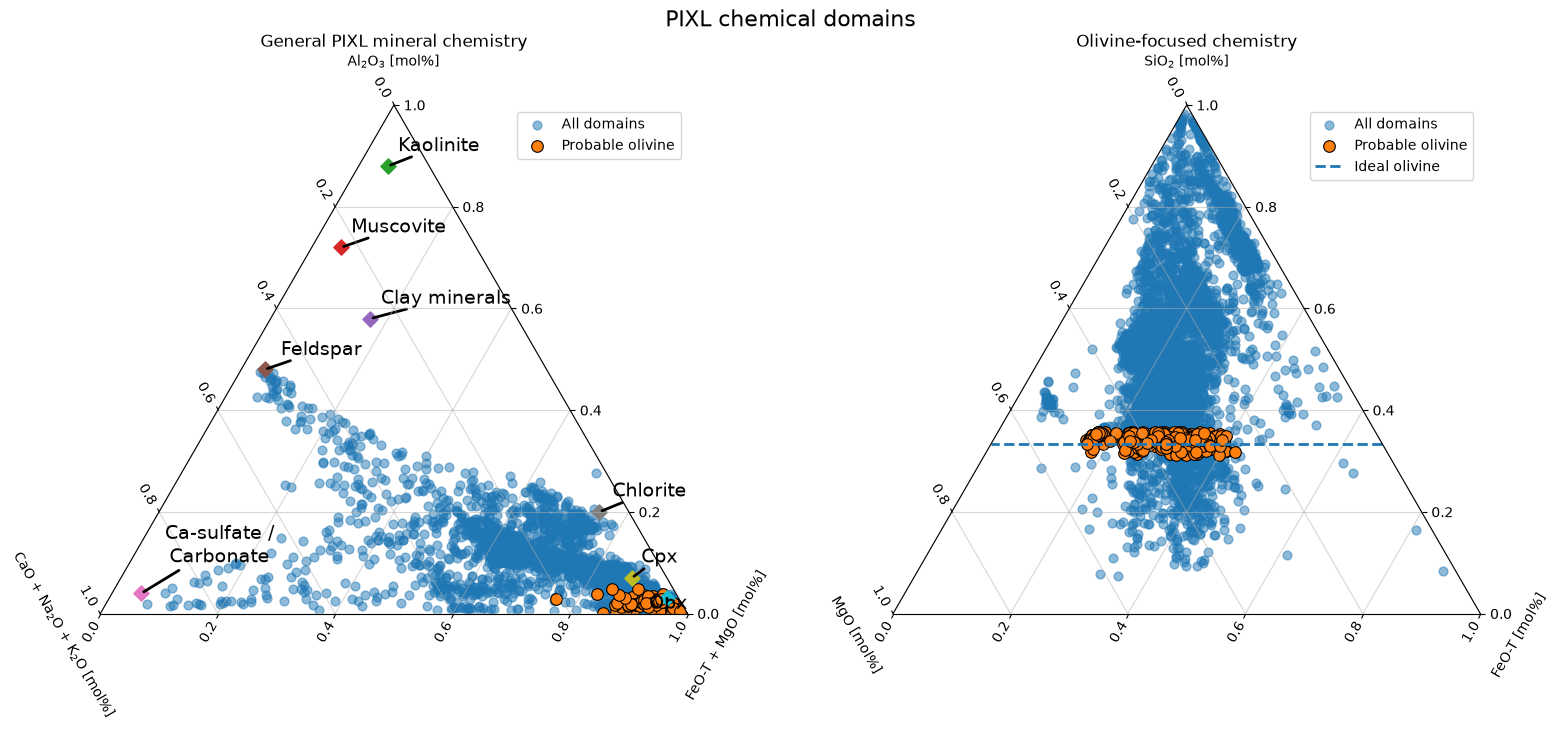

In [3]:
threshold = 30

fig, tax1, tax2 = mineral.plot_both_ternary(
domain_data,
threshold
)
plt.savefig(
    Path(f"pixl_cache/target_analysis/_AllTargets_Ternary_T{threshold}.svg"),
    format="svg"
)
plt.show()
plt.close()

In [8]:
#Add location data to DataFrame for every target and write to .csv
#load location data
location_data = pd.read_csv("pixl_cache/location/best_interp.csv")
#new dataFrame with all relevant information with 1 row for each sol
sol_locations = location_data.drop_duplicates(
    subset="sol",
    keep="first"
).copy()
sol_locations = sol_locations.rename(
    columns={"sol": "SOL"}
)
#get all sols of observations
observation_sols = domain_data["SOL"].drop_duplicates()
nearest_sols = [
    sol_locations.loc[
        (sol_locations["SOL"] - sol).abs().idxmin(),
        "SOL"
    ]
    for sol in observation_sols
]
sol_matches = pd.DataFrame({"observation_sol": observation_sols,"location_sol": nearest_sols})
domain_data_location = domain_data.merge(
    sol_matches,
    left_on="SOL",
    right_on="observation_sol",
    how="inner"
)
domain_data_location = domain_data_location.merge(
    sol_locations,
    left_on="location_sol",
    right_on="SOL",
    how="inner"
)
domain_data_location.to_csv(Path(f"pixl_cache/target_analysis/_AllTargets_Summary_Locations_T{threshold}.csv"))


In [17]:
import pandas as pd

domain_data_location = pd.read_csv(
    Path(f"pixl_cache/target_analysis/_AllTargets_Summary_Locations_T{threshold}.csv")
)
#
olivine_locations = (
    domain_data_location
    .groupby(["target","longitude", "planetocentric_latitude"])
    .apply(
        lambda x: pd.Series({
            "olivine_pixels": x.loc[
                x["is_olivine_candidate"], "n_points"
            ].sum(),
            "total_pixels": x["n_points"].sum()
        }),
        include_groups=False
    )
    .reset_index()
)

olivine_locations["olivine_ratio"] = (
    olivine_locations["olivine_pixels"]
    / olivine_locations["total_pixels"]
)*100
olivine_locations.to_csv(
    "pixl_cache/target_analysis/olivine_locations.csv",
    index=False
)

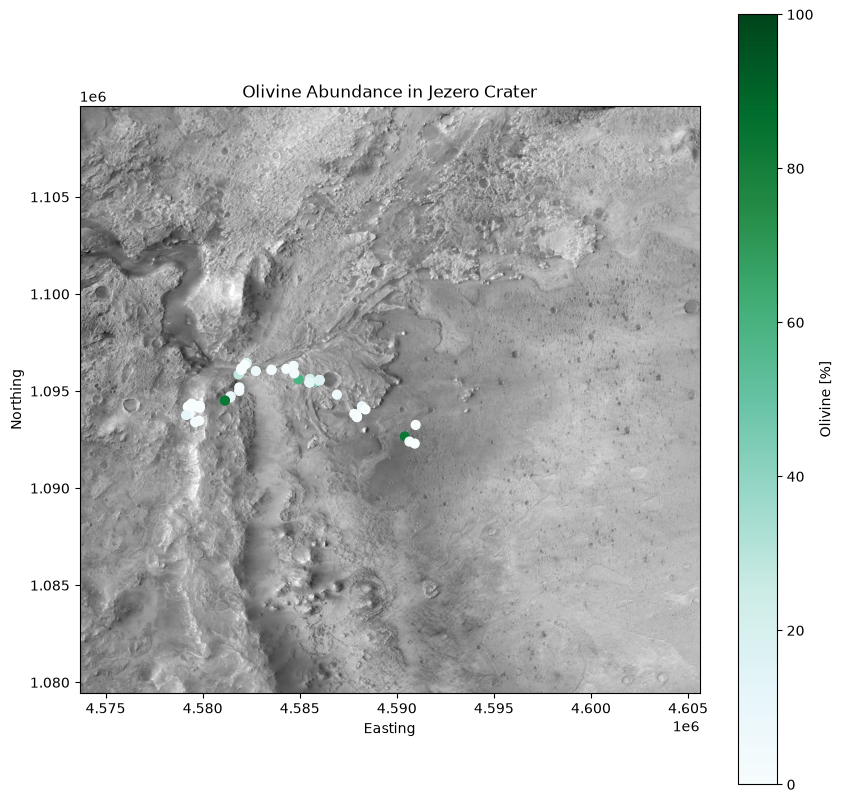

0.11610296429165819


In [25]:
import rasterio
import numpy as np
import pandas as pd

olivine_locations = pd.read_csv(Path(f"pixl_cache/target_analysis/olivine_locations.csv"))
#


with rasterio.open("pixl_cache/maps/Jezero.tiff") as src:
    image = src.read(1)
    bounds = src.bounds

R = 3396190

olivine_locations["E"] = (
    np.deg2rad(olivine_locations["longitude"]) * R
)
olivine_locations["N"] = (
    np.deg2rad(olivine_locations["planetocentric_latitude"]) * R
)


fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(
    image,
    extent=[
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ],
    cmap="gray"
)
scatter = ax.scatter(
    olivine_locations["E"],
    olivine_locations["N"],
    c=olivine_locations["olivine_ratio"],
    cmap="BuGn",
    s=40
)
plt.colorbar(
    scatter,
    ax=ax,
    label="Olivine [%]"
)

ax.set_xlabel("Easting")
ax.set_ylabel("Northing")
ax.set_aspect("equal")
plt.title("Olivine Abundance in Jezero Crater")
plt.savefig(
    Path(f"images_export/Map_OlPerc.svg"),
    format="svg"
)
plt.show()


print(f"{sum(olivine_locations["olivine_pixels"])/sum(olivine_locations["total_pixels"])}")

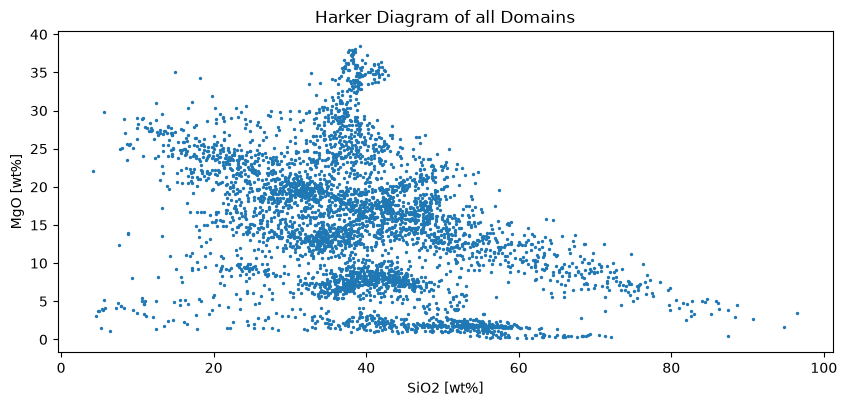

In [10]:
# Create Harker Diagram of all locations
fig, ax = plt.subplots(
    figsize=(10, 6)
)
#
ax.scatter(
    domain_data["SiO2_wt%"],
    domain_data["MgO_wt%"],
    marker="o",
    s = 2
)
ax.set_xlabel("SiO2 [wt%]")
ax.set_ylabel("MgO [wt%]")
ax.set_aspect("equal")
ax.set_title(
    f"Harker Diagram of all Domains"
)
plt.savefig(
            Path(f"pixl_cache/target_analysis//Harker_SiO2_MgO.svg"),
            format="svg"
)
plt.show()

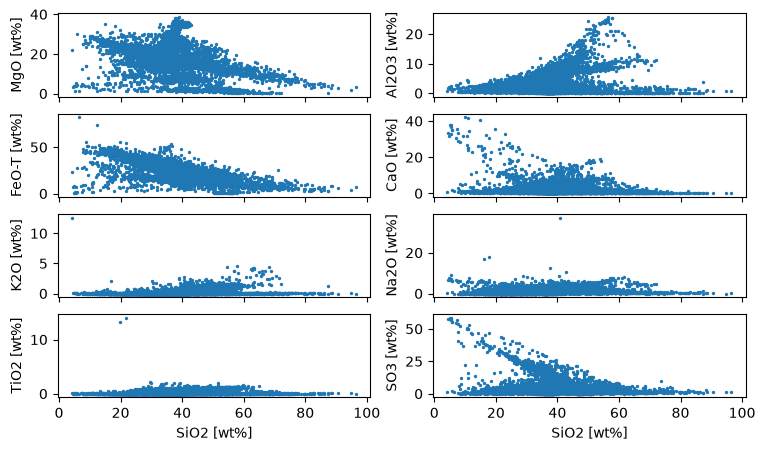

In [21]:
# Create Harker Diagram of all locations
fig, axes = plt.subplots(nrows=4, ncols=2, sharex=True)
ax0, ax1, ax2, ax3, ax4, ax5, ax6, ax7 = axes.flatten()
#
ax0.scatter(
    domain_data["SiO2_wt%"],
    domain_data["MgO_wt%"],
    marker="o",
    s = 2
)
ax0.set_ylabel("MgO [wt%]")
#
ax1.scatter(
    domain_data["SiO2_wt%"],
    domain_data["Al2O3_wt%"],
    marker="o",
    s = 2
)
ax1.set_ylabel("Al2O3 [wt%]")
#
ax2.scatter(
    domain_data["SiO2_wt%"],
    domain_data["FeO-T_wt%"],
    marker="o",
    s = 2
)
ax2.set_ylabel("FeO-T [wt%]")
#
ax3.scatter(
    domain_data["SiO2_wt%"],
    domain_data["CaO_wt%"],
    marker="o",
    s = 2
)
ax3.set_ylabel("CaO [wt%]")
#
ax4.scatter(
    domain_data["SiO2_wt%"],
    domain_data["K2O_wt%"],
    marker="o",
    s = 2
)
ax4.set_ylabel("K2O [wt%]")
#
ax5.scatter(
    domain_data["SiO2_wt%"],
    domain_data["Na2O_wt%"],
    marker="o",
    s = 2
)
ax5.set_ylabel("Na2O [wt%]")
#
ax6.scatter(
    domain_data["SiO2_wt%"],
    domain_data["TiO2_wt%"],
    marker="o",
    s = 2
)
ax6.set_ylabel("TiO2 [wt%]")
#
ax7.scatter(
    domain_data["SiO2_wt%"],
    domain_data["SO3_wt%"],
    marker="o",
    s = 2
)
ax7.set_ylabel("SO3 [wt%]")


ax6.set_xlabel("SiO2 [wt%]")
ax7.set_xlabel("SiO2 [wt%]")
#plt.set_title(f"Harker Diagram of all Domains")
plt.subplots_adjust(bottom=0.1, right=1.2, top=0.9)
plt.savefig(
            Path(f"pixl_cache/target_analysis//Harker_ALL.svg"),
            format="svg",
            bbox_inches = "tight"
)
plt.show()

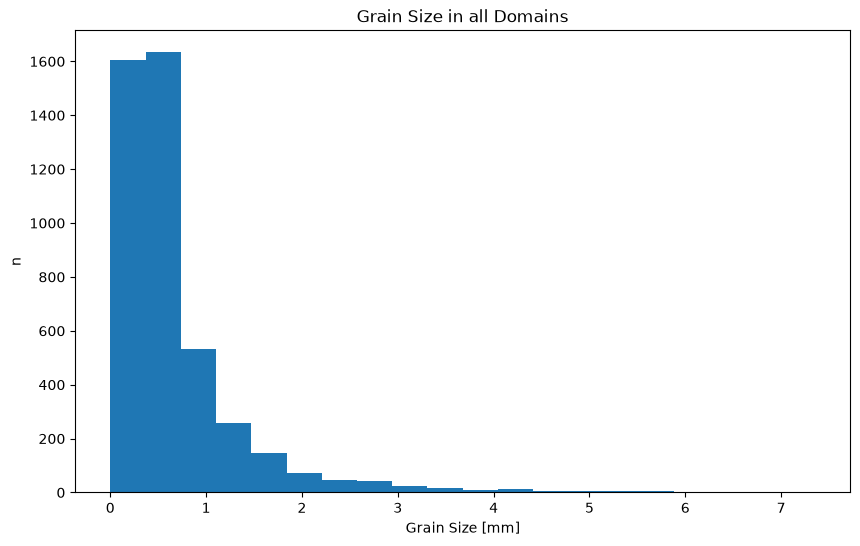

In [24]:
# Create Diagram of all locations
fig, ax = plt.subplots(
    figsize=(10, 6)
)
#
ax.hist(
    domain_data["mean_width_mm"],
    bins=20
    
)
ax.set_xlabel("Grain Size [mm]")
ax.set_ylabel("n")
ax.set_title(
    f"Grain Size in all Domains"
)
plt.savefig(
            Path(f"pixl_cache/target_analysis/GrainSize.svg"),
            format="svg"
)
plt.show()